# 04 — Analisis: Signifikansi (RQ1–2), Learning Curve (RQ4), Truncation & Kualitatif

1. **Tabel utama Eksp. 1** — μ ± σ dari 3 seed.
2. **Uji signifikansi per kueri (n = 960)** pada nDCG@10 (rata-rata 3 seed per kueri): Shapiro-Wilk pada selisih → paired t-test bila normal, Wilcoxon signed-rank bila tidak; selisih rata-rata + 95% CI; koreksi Holm untuk 3 perbandingan. Kriteria *"lebih efektif"*: p < 0,05 **dan** |Δ| ≥ 0,01.
3. **Efisiensi** mBERT vs mDeBERTa (dari notebook 02).
4. **Eksp. 3** — learning curve nDCG@10 vs proporsi data latih (deskriptif, 1 seed).
5. **Truncation** — % pasangan yang terpotong pada 256 token per tokenizer.
6. **Analisis kualitatif** — kueri yang berhasil/gagal ditingkatkan, dan pola leksikal vs semantik.

> Tidak memerlukan GPU.

## 1. Setup

In [1]:
!pip -q install pytrec-eval-terrier sentencepiece protobuf

In [2]:
# Mount Google Drive: semua data, skor, dan hasil disimpan di sini agar aman
# bila sesi Colab terputus.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

BASE_DIR    = '/content/drive/MyDrive/MIRACL_Reranking'   # ubah bila perlu
DATA_DIR    = f'{BASE_DIR}/data'      # topics, qrels, BM25 run, passages, training pairs
SCORES_DIR  = f'{BASE_DIR}/scores'    # skor cross-encoder per run (Dev top-100)
RESULTS_DIR = f'{BASE_DIR}/results'   # metrik (JSON), tabel (CSV), log
FIG_DIR     = f'{BASE_DIR}/figures'   # grafik (PNG)
for d in [DATA_DIR, SCORES_DIR, RESULTS_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)
print('BASE_DIR =', BASE_DIR)

BASE_DIR = /content/drive/MyDrive/MIRACL_Reranking


In [4]:
import json
import pandas as pd

def read_qrels(path):
    """Baca qrels format TREC (qid Q0 docid rel) -> {qid: {docid: rel}}."""
    qrels = {}
    with open(path) as f:
        for line in f:
            p = line.split()
            if len(p) < 4:
                continue
            qrels.setdefault(str(p[0]), {})[p[2]] = int(p[3])
    return qrels

def read_run(path):
    """Baca run format TREC -> {qid: [(docid, score), ...]} terurut berdasarkan rank."""
    tmp = {}
    with open(path) as f:
        for line in f:
            qid, _, docid, rank, score, _tag = line.split()
            tmp.setdefault(qid, []).append((int(rank), docid, float(score)))
    return {q: [(d, s) for _, d, s in sorted(v)] for q, v in tmp.items()}

topics = pd.read_parquet(f'{DATA_DIR}/topics.parquet')            # qid, split, query
QUERY  = dict(zip(topics.qid, topics['query']))
with open(f'{DATA_DIR}/splits.json') as f:
    SPLITS = json.load(f)
qrels_train = read_qrels(f'{DATA_DIR}/qrels.train.tsv')
qrels_dev   = read_qrels(f'{DATA_DIR}/qrels.dev.tsv')
bm25_train  = read_run(f'{DATA_DIR}/run.bm25.train.top100.txt')
bm25_dev    = read_run(f'{DATA_DIR}/run.bm25.dev.top100.txt')
print({k: len(v) for k, v in SPLITS.items()})
print('Dev queries di run BM25:', len(bm25_dev))

{'train': 3664, 'val': 407, 'dev': 960, 'train_25': 916, 'train_50': 1832}
Dev queries di run BM25: 960


In [5]:
import numpy as np
import pandas as pd
import pytrec_eval

def ranking_to_run(ranking):
    """{qid: [docid urut]} -> {qid: {docid: skor}} dengan skor menurun sesuai rank,
    sehingga pytrec_eval memakai urutan persis seperti daftar (tanpa efek tie)."""
    return {q: {d: float(len(docs) - i) for i, d in enumerate(docs)}
            for q, docs in ranking.items()}

def evaluate(ranking, qrels, recall_ks=(20, 50, 100)):
    """Hitung nDCG@10, MRR@10, MAP@100, Recall@k.

    ranking : {qid: [docid, ...]} terurut (maks. 100 dokumen)
    qrels   : {qid: {docid: rel}}
    Hanya kueri yang punya >=1 dokumen relevan yang dievaluasi; kueri yang
    tidak ada di ranking diberi skor 0 (bukan dibuang).
    Return: (rata-rata dict, DataFrame per kueri)
    """
    qids = sorted(q for q, rels in qrels.items() if any(r > 0 for r in rels.values()))
    q_sub = {q: qrels[q] for q in qids}
    full = ranking_to_run({q: ranking.get(q, []) for q in qids})
    top10 = ranking_to_run({q: ranking.get(q, [])[:10] for q in qids})
    # pytrec_eval melewati kueri dengan run kosong -> isi dummy agar tetap terhitung 0
    for run in (full, top10):
        for q in qids:
            if not run[q]:
                run[q] = {'__none__': 0.0}

    rec_spec = 'recall.' + ','.join(str(k) for k in recall_ks)
    ev_full = pytrec_eval.RelevanceEvaluator(q_sub, {'ndcg_cut.10', 'map_cut.100', rec_spec})
    ev_top10 = pytrec_eval.RelevanceEvaluator(q_sub, {'recip_rank'})
    r_full, r_top10 = ev_full.evaluate(full), ev_top10.evaluate(top10)

    rows = []
    for q in qids:
        row = {'qid': q,
               'ndcg@10': r_full[q]['ndcg_cut_10'],
               'mrr@10': r_top10[q]['recip_rank'],
               'map@100': r_full[q]['map_cut_100']}
        for k in recall_ks:
            row[f'recall@{k}'] = r_full[q][f'recall_{k}']
        rows.append(row)
    per_q = pd.DataFrame(rows).set_index('qid')
    return per_q.mean().to_dict(), per_q

In [6]:
import matplotlib.pyplot as plt

# Warna tetap per entitas (tidak berubah antar grafik)
COLORS = {'BM25': '#7a7974', 'mBERT': '#2a78d6', 'mDeBERTa': '#eb6834'}
MARKERS = {'BM25': 's', 'mBERT': 'o', 'mDeBERTa': '^'}
plt.rcParams.update({
    'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
    'lines.linewidth': 2, 'lines.markersize': 8, 'font.size': 10,
})
MODEL_LABEL = {'mbert': 'mBERT', 'mdeberta': 'mDeBERTa'}

In [7]:
from scipy import stats

SEEDS = [42, 100, 2026]
MODEL_KEYS = ['mbert', 'mdeberta']
ALPHA, MIN_DELTA = 0.05, 0.01
METRICS = ['ndcg@10', 'mrr@10', 'map@100', 'recall@100']

def load_result(name):
    p = f'{RESULTS_DIR}/{name}.json'
    return json.load(open(p)) if os.path.exists(p) else None

def load_perq(name):
    p = f'{RESULTS_DIR}/{name}.per_query.csv'
    return pd.read_csv(p, dtype={'qid': str}).set_index('qid') if os.path.exists(p) else None

bm25_perq = pd.read_csv(f'{RESULTS_DIR}/bm25_dev_per_query.csv', dtype={'qid': str}).set_index('qid')
perq = {m: {s: load_perq(f'{m}_frac100_seed{s}') for s in SEEDS} for m in MODEL_KEYS}
for m in MODEL_KEYS:
    print(m, 'seed tersedia:', [s for s, v in perq[m].items() if v is not None])

mbert seed tersedia: [42, 100, 2026]
mdeberta seed tersedia: [42, 100, 2026]


## 2. Tabel utama Eksp. 1 (Dev, k = 100)

In [8]:
rows = [{'Sistem': 'BM25 (tanpa rerank)', **{k: f'{bm25_perq[k].mean():.4f}' for k in METRICS}}]
for m in MODEL_KEYS:
    seed_means = pd.DataFrame([v[METRICS].mean() for v in perq[m].values() if v is not None])
    if not len(seed_means):
        continue
    rows.append({'Sistem': f'BM25 + {MODEL_LABEL[m]}-FT (n={len(seed_means)} seed)',
                 **{k: f'{seed_means[k].mean():.4f} ± {seed_means[k].std(ddof=1):.4f}' for k in METRICS}})
main_table = pd.DataFrame(rows).set_index('Sistem')
main_table.to_csv(f'{RESULTS_DIR}/table_exp1_main.csv')
main_table

,ndcg@10,mrr@10,map@100,recall@100
Sistem,,,,
BM25 (tanpa rerank),0.4486,0.5306,0.3893,0.9041
BM25 + mBERT-FT (n=3 seed),0.5947 ± 0.0056,0.6956 ± 0.0058,0.5159 ± 0.0051,0.9041 ± 0.0000
BM25 + mDeBERTa-FT (n=3 seed),0.6035 ± 0.0060,0.7053 ± 0.0064,0.5301 ± 0.0061,0.9041 ± 0.0000


## 3. Uji signifikansi (RQ1 & RQ2)

In [9]:
def seed_avg(m, metric):
    cols = [v[metric] for v in perq[m].values() if v is not None]
    return pd.concat(cols, axis=1).mean(axis=1) if cols else None

def holm(pvals):
    """Koreksi Holm-Bonferroni."""
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

def paired_test(a, b, n_boot=10000, seed=0):
    """a - b per kueri. Return dict statistik."""
    a, b = a.align(b, join='inner')
    d = (a - b).values
    n = len(d)
    mean, sd = d.mean(), d.std(ddof=1)
    t_ci = stats.t.interval(0.95, n - 1, loc=mean, scale=sd / np.sqrt(n))
    rng = np.random.default_rng(seed)
    boot = rng.choice(d, (n_boot, n), replace=True).mean(axis=1)
    shapiro_p = stats.shapiro(d).pvalue
    t_p = stats.ttest_rel(a.values, b.values).pvalue
    w_p = stats.wilcoxon(a.values, b.values).pvalue if np.any(d != 0) else 1.0
    normal = shapiro_p >= ALPHA
    return {'n': n, 'mean_A': a.mean(), 'mean_B': b.mean(), 'delta': mean,
            'ci95_t': t_ci, 'ci95_boot': (np.percentile(boot, 2.5), np.percentile(boot, 97.5)),
            'shapiro_p': shapiro_p, 'normal': normal, 't_p': t_p, 'wilcoxon_p': w_p,
            'test': 'paired t-test' if normal else 'Wilcoxon', 'p': t_p if normal else w_p,
            'win/tie/loss': f'{(d > 0).sum()}/{(d == 0).sum()}/{(d < 0).sum()}'}

def run_tests(metric):
    systems = {'BM25': bm25_perq[metric]}
    for m in MODEL_KEYS:
        s = seed_avg(m, metric)
        if s is not None:
            systems[MODEL_LABEL[m]] = s
    comps = [('mBERT', 'BM25'), ('mDeBERTa', 'BM25'), ('mDeBERTa', 'mBERT')]
    comps = [c for c in comps if c[0] in systems and c[1] in systems]
    res = [{'A': a, 'B': b, **paired_test(systems[a], systems[b])} for a, b in comps]
    adj = holm([r['p'] for r in res]) if res else []
    for r, pa in zip(res, adj):
        r['p_holm'] = pa
        r['signifikan'] = pa < ALPHA
        r['lebih efektif (p<.05 & |Δ|≥.01)'] = bool(pa < ALPHA and abs(r['delta']) >= MIN_DELTA)
    df = pd.DataFrame(res)
    if len(df):
        df['ci95_t'] = df.ci95_t.map(lambda x: f'[{x[0]:+.4f}, {x[1]:+.4f}]')
        df['ci95_boot'] = df.ci95_boot.map(lambda x: f'[{x[0]:+.4f}, {x[1]:+.4f}]')
    return df

sig_ndcg = run_tests('ndcg@10')
sig_mrr = run_tests('mrr@10')
sig_ndcg.to_csv(f'{RESULTS_DIR}/significance_ndcg10.csv', index=False)
sig_mrr.to_csv(f'{RESULTS_DIR}/significance_mrr10.csv', index=False)
print('nDCG@10 (utama):')
display(sig_ndcg.round(4))
print('MRR@10 (sekunder):')
display(sig_mrr.round(4))

nDCG@10 (utama):


,A,B,n,mean_A,mean_B,delta,ci95_t,ci95_boot,shapiro_p,normal,t_p,wilcoxon_p,test,p,win/tie/loss,p_holm,signifikan,lebih efektif (p<.05 & |Δ|≥.01)
0,mBERT,BM25,960,0.5947,0.4486,0.1462,"[+0.1245, +0.1678]","[+0.1247, +0.1683]",0.0,False,0.0000,0.0000,Wilcoxon,0.0000,578/128/254,0.0000,True,True
1,mDeBERTa,BM25,960,0.6035,0.4486,0.1550,"[+0.1340, +0.1759]","[+0.1340, +0.1765]",0.0,False,0.0000,0.0000,Wilcoxon,0.0000,589/131/240,0.0000,True,True
2,mDeBERTa,mBERT,960,0.6035,0.5947,0.0088,"[-0.0003, +0.0179]","[-0.0000, +0.0178]",0.0,False,0.0577,0.1835,Wilcoxon,0.1835,394/188/378,0.1835,False,False


MRR@10 (sekunder):


,A,B,n,mean_A,mean_B,delta,ci95_t,ci95_boot,shapiro_p,normal,t_p,wilcoxon_p,test,p,win/tie/loss,p_holm,signifikan,lebih efektif (p<.05 & |Δ|≥.01)
0,mBERT,BM25,960,0.6956,0.5306,0.1651,"[+0.1378, +0.1924]","[+0.1376, +0.1925]",0.0,False,0.0000,0.0000,Wilcoxon,0.0000,432/316/212,0.0000,True,True
1,mDeBERTa,BM25,960,0.7053,0.5306,0.1748,"[+0.1481, +0.2014]","[+0.1481, +0.2017]",0.0,False,0.0000,0.0000,Wilcoxon,0.0000,446/325/189,0.0000,True,True
2,mDeBERTa,mBERT,960,0.7053,0.6956,0.0097,"[-0.0022, +0.0216]","[-0.0021, +0.0219]",0.0,False,0.1115,0.2156,Wilcoxon,0.2156,249/478/233,0.2156,False,False


**Catatan:** dengan n = 960, Shapiro-Wilk hampir selalu menolak normalitas (distribusi selisih nDCG per kueri biasanya berat di 0), sehingga Wilcoxon umumnya menjadi uji yang dipakai; p-value t-test tetap dilaporkan sebagai pembanding. Wilcoxon (zero_method default) membuang selisih nol.

In [10]:
def verdict(df):
    for _, r in df.iterrows():
        tag = '✅ lebih efektif' if r['lebih efektif (p<.05 & |Δ|≥.01)'] else (
              '≈ signifikan tapi Δ < 0,01' if r['signifikan'] else '✗ tidak signifikan')
        print(f"{r.A} vs {r.B}: Δ nDCG@10 = {r.delta:+.4f} {r.ci95_t} | {r.test} p(Holm) = {r.p_holm:.2e} → {tag}")
verdict(sig_ndcg)

mBERT vs BM25: Δ nDCG@10 = +0.1462 [+0.1245, +0.1678] | Wilcoxon p(Holm) = 8.64e-36 → ✅ lebih efektif
mDeBERTa vs BM25: Δ nDCG@10 = +0.1550 [+0.1340, +0.1759] | Wilcoxon p(Holm) = 1.24e-41 → ✅ lebih efektif
mDeBERTa vs mBERT: Δ nDCG@10 = +0.0088 [-0.0003, +0.0179] | Wilcoxon p(Holm) = 1.83e-01 → ✗ tidak signifikan


## 4. Efisiensi mBERT vs mDeBERTa (RQ2, seed 42, L4)

In [11]:
eff = []
for m in MODEL_KEYS:
    p = f'{RESULTS_DIR}/efficiency_{m}.json'
    if os.path.exists(p):
        e = json.load(open(p)); v = e['by_k']['100']
        eff.append({'Model': MODEL_LABEL[m], 'Parameter (M)': e['n_params'] / 1e6,
                    'Memori bobot (MB)': e['weights_mem_mb'],
                    'Latency k=100 (ms/kueri)': v['latency_ms_mean'], 'p95 (ms)': v['latency_ms_p95'],
                    'Throughput (pasangan/s)': v['throughput_pairs_per_s'],
                    'Puncak memori GPU (MB)': v['peak_gpu_mem_mb']})
eff_table = pd.DataFrame(eff).set_index('Model') if eff else pd.DataFrame()
if len(eff_table) == 2:
    eff_table.loc['Rasio mDeBERTa / mBERT'] = eff_table.loc['mDeBERTa'] / eff_table.loc['mBERT']
eff_table.to_csv(f'{RESULTS_DIR}/table_efficiency.csv')
eff_table.round(3)

,Parameter (M),Memori bobot (MB),Latency k=100 (ms/kueri),p95 (ms),Throughput (pasangan/s),Puncak memori GPU (MB)
Model,,,,,,
mBERT,177.854,678.460,177.195,187.123,560.357,1062.391
mDeBERTa,278.810,1063.576,501.061,519.653,198.165,1933.316
Rasio mDeBERTa / mBERT,1.568,1.568,2.828,2.777,0.354,1.820


In [12]:
# Waktu training rata-rata per run (Eksp. 1)
tt = []
for m in MODEL_KEYS:
    for s in SEEDS:
        r = load_result(f'{m}_frac100_seed{s}')
        if r: tt.append({'Model': MODEL_LABEL[m], 'seed': s, 'menit training': r['train_minutes'],
                         'epoch terbaik': r['best_epoch'], 'val nDCG@10': r['val_best']['ndcg@10']})
pd.DataFrame(tt).round(3)

,Model,seed,menit training,epoch terbaik,val nDCG@10
0,mBERT,42,25.254,2,0.608
1,mBERT,100,25.054,3,0.594
2,mBERT,2026,25.054,2,0.602
3,mDeBERTa,42,53.404,2,0.606
4,mDeBERTa,100,53.385,3,0.606
5,mDeBERTa,2026,53.403,3,0.612


## 5. Eksp. 3 — Pengaruh ukuran data latih (RQ4, deskriptif)

In [13]:
lc = []
for m in MODEL_KEYS:
    for frac in [25, 50]:
        r = load_result(f'{m}_frac{frac}_seed42')
        if r: lc.append({'model': MODEL_LABEL[m], 'frac': frac, 'ndcg@10': r['dev_k100']['ndcg@10'],
                         'mrr@10': r['dev_k100']['mrr@10'], 'std': np.nan, 'n_queries': r['n_train_queries']})
    full = [load_result(f'{m}_frac100_seed{s}') for s in SEEDS]
    full = [r for r in full if r]
    if full:
        v = [r['dev_k100']['ndcg@10'] for r in full]
        lc.append({'model': MODEL_LABEL[m], 'frac': 100, 'ndcg@10': np.mean(v),
                   'mrr@10': np.mean([r['dev_k100']['mrr@10'] for r in full]),
                   'std': np.std(v, ddof=1) if len(v) > 1 else np.nan, 'n_queries': full[0]['n_train_queries']})
lc = pd.DataFrame(lc)
if len(lc):
    lc = lc.sort_values(['model', 'frac'])
    lc['Δ vs 100%'] = lc.groupby('model')['ndcg@10'].transform(lambda s: s - s.iloc[-1])
    lc.to_csv(f'{RESULTS_DIR}/table_exp3_learning_curve.csv', index=False)
    display(lc.round(4))

,model,frac,ndcg@10,mrr@10,std,n_queries,Δ vs 100%
0,mBERT,25,0.5492,0.6468,NaN,916,-0.0455
1,mBERT,50,0.5725,0.6700,NaN,1832,-0.0222
2,mBERT,100,0.5947,0.6956,0.0056,3664,0.0000
3,mDeBERTa,25,0.5715,0.6694,NaN,916,-0.0321
4,mDeBERTa,50,0.5891,0.6895,NaN,1832,-0.0144
5,mDeBERTa,100,0.6035,0.7053,0.0060,3664,0.0000


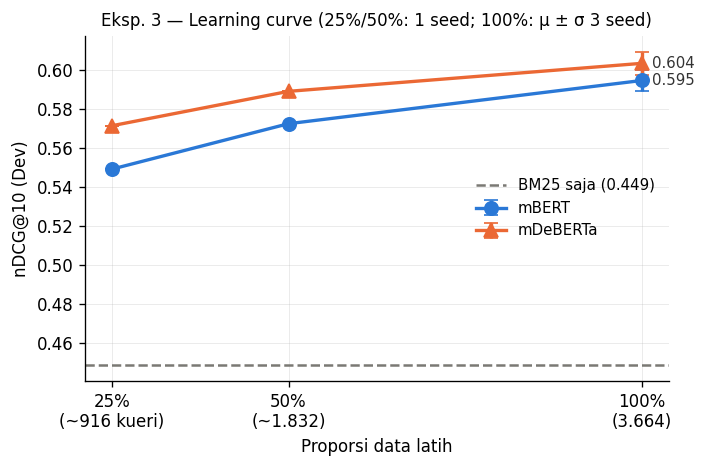

In [14]:
if len(lc):
    fig, ax = plt.subplots(figsize=(6, 4))
    for m in ['mBERT', 'mDeBERTa']:
        d = lc[lc.model == m]
        if not len(d): continue
        ax.errorbar(d.frac, d['ndcg@10'], yerr=d['std'].fillna(0), color=COLORS[m],
                    marker=MARKERS[m], capsize=4, label=m)
        last = d.iloc[-1]
        ax.annotate(f"{last['ndcg@10']:.3f}", (last.frac, last['ndcg@10']), textcoords='offset points',
                    xytext=(6, 0), va='center', fontsize=9, color='#333')
    bm = bm25_perq['ndcg@10'].mean()
    ax.axhline(bm, color=COLORS['BM25'], ls='--', lw=1.5, label=f'BM25 saja ({bm:.3f})')
    ax.set_xticks([25, 50, 100]); ax.set_xticklabels(['25%\n(~916 kueri)', '50%\n(~1.832)', '100%\n(3.664)'])
    ax.set_xlabel('Proporsi data latih'); ax.set_ylabel('nDCG@10 (Dev)')
    ax.set_title('Eksp. 3 — Learning curve (25%/50%: 1 seed; 100%: μ ± σ 3 seed)', fontsize=10)
    ax.legend(frameon=False, fontsize=9)
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/exp3_learning_curve.png', dpi=200, bbox_inches='tight'); plt.show()

## 6. Truncation pada max length 256 (threat to validity)

Persentase pasangan (query + passage) yang melebihi 256 token untuk tiap tokenizer, pada kandidat top-100 Dev dan pasangan latih. Perbedaan tokenizer (WordPiece ~119k vs SentencePiece ~250k) membuat jumlah token berbeda untuk teks yang sama.

In [15]:
from transformers import AutoTokenizer
pass_df = pd.read_parquet(f'{DATA_DIR}/passages.parquet')
PASSAGE = {d: f'{(t or "").strip()} {(x or "").strip()}'.strip()
           for d, t, x in zip(pass_df.docid, pass_df.title, pass_df.text)}
pairs_all = pd.read_parquet(f'{DATA_DIR}/train_pairs.parquet')
CKPT = {'mbert': 'bert-base-multilingual-cased', 'mdeberta': 'microsoft/mdeberta-v3-base'}

dev_pairs = [(q, d) for q in SPLITS['dev'] for d, _ in bm25_dev[q]]
sets = {'Dev top-100': dev_pairs, 'Pasangan latih': list(zip(pairs_all.qid, pairs_all.docid))}
trunc = []
for m, ck in CKPT.items():
    tok = AutoTokenizer.from_pretrained(ck)
    for name, pr in sets.items():
        lens = []
        for i in range(0, len(pr), 4096):
            ch = pr[i:i + 4096]
            enc = tok([QUERY[q] for q, _ in ch], [PASSAGE[d] for _, d in ch], truncation=False)
            lens += [len(x) for x in enc['input_ids']]
        lens = np.array(lens)
        trunc.append({'Tokenizer': MODEL_LABEL[m], 'Set': name, 'n pasangan': len(lens),
                      'median token': np.median(lens), 'p95 token': np.percentile(lens, 95),
                      '% > 256 (terpotong)': 100 * (lens > 256).mean()})
trunc = pd.DataFrame(trunc)
trunc.to_csv(f'{RESULTS_DIR}/table_truncation.csv', index=False)
trunc.round(2)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (517 > 512). Running this sequence through the model will result in indexing errors


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

,Tokenizer,Set,n pasangan,median token,p95 token,% > 256 (terpotong)
0,mBERT,Dev top-100,95310,121.0,294.0,8.10
1,mBERT,Pasangan latih,44814,145.0,321.0,11.30
2,mDeBERTa,Dev top-100,95310,135.0,325.0,11.36
3,mDeBERTa,Pasangan latih,44814,161.0,356.0,16.23


## 7. Analisis kualitatif

Selisih nDCG@10 per kueri terhadap BM25 (rata-rata 3 seed). Kategori:
- **Keduanya berhasil**: kedua model naik paling besar.
- **Keduanya gagal**: kedua model turun dibanding BM25.
- **Berbeda pendapat**: satu model jauh lebih baik dari yang lain.

Daftar teratas ditampilkan bersama passage peringkat 1 dari setiap sistem (✔ = relevan menurut qrels). Peringkat model diambil dari run seed 42.

In [16]:
def ranking_from_scores(name):
    p = f'{SCORES_DIR}/{name}.dev_top100.parquet'
    if not os.path.exists(p): return None
    sc = pd.read_parquet(p)
    return {q: g.sort_values(['ce_score', 'bm25_rank'], ascending=[False, True]).docid.tolist()
            for q, g in sc.groupby('qid', sort=False)}

rank42 = {MODEL_LABEL[m]: ranking_from_scores(f'{m}_frac100_seed42') for m in MODEL_KEYS}
rank42['BM25'] = {q: [d for d, _ in v] for q, v in bm25_dev.items()}

nd = pd.DataFrame({'BM25': bm25_perq['ndcg@10']})
for m in MODEL_KEYS:
    s = seed_avg(m, 'ndcg@10')
    if s is not None: nd[MODEL_LABEL[m]] = s
nd['query'] = nd.index.map(QUERY)
have_both = {'mBERT', 'mDeBERTa'} <= set(nd.columns)
if have_both:
    nd['Δ mBERT'] = nd.mBERT - nd.BM25
    nd['Δ mDeBERTa'] = nd.mDeBERTa - nd.BM25
    nd['mDeBERTa − mBERT'] = nd.mDeBERTa - nd.mBERT
    cat = pd.Series('lainnya', index=nd.index)
    cat[(nd['Δ mBERT'] > 0) & (nd['Δ mDeBERTa'] > 0)] = 'keduanya naik'
    cat[(nd['Δ mBERT'] < 0) & (nd['Δ mDeBERTa'] < 0)] = 'keduanya turun'
    cat[(nd['Δ mBERT'] == 0) & (nd['Δ mDeBERTa'] == 0)] = 'sama dengan BM25'
    nd['kategori'] = cat
    display(nd.kategori.value_counts().to_frame('jumlah kueri'))

,jumlah kueri
kategori,
keduanya naik,528
keduanya turun,187
lainnya,139
sama dengan BM25,106


In [17]:
def show_case(q, top=1, maxlen=220):
    rels = {d for d, r in qrels_dev.get(q, {}).items() if r > 0}
    print(f'Q[{q}]: {QUERY[q]}')
    print('   nDCG@10 → ' + ' | '.join(f'{c}: {nd.loc[q, c]:.3f}' for c in ['BM25', 'mBERT', 'mDeBERTa'] if c in nd))
    if rels:
        d0 = sorted(rels)[0]
        print(f'   relevan (contoh): {PASSAGE.get(d0, "")[:maxlen]}')
    for sysname, rk in rank42.items():
        if rk is None: continue
        for i, d in enumerate(rk.get(q, [])[:top], 1):
            mark = '✔' if d in rels else '✗'
            print(f'   {sysname:>8} #{i} {mark} {PASSAGE.get(d, "")[:maxlen]}')
    print()

if have_both:
    print('==== Keduanya naik paling besar ====')
    for q in (nd['Δ mBERT'] + nd['Δ mDeBERTa']).nlargest(3).index: show_case(q)
    print('==== Keduanya turun paling besar ====')
    for q in (nd['Δ mBERT'] + nd['Δ mDeBERTa']).nsmallest(3).index: show_case(q)
    print('==== mDeBERTa jauh lebih baik dari mBERT ====')
    for q in nd['mDeBERTa − mBERT'].nlargest(2).index: show_case(q)
    print('==== mBERT jauh lebih baik dari mDeBERTa ====')
    for q in nd['mDeBERTa − mBERT'].nsmallest(2).index: show_case(q)

==== Keduanya naik paling besar ====
Q[1082]: Berapa populasi pemeluk agama islam di Indonesi tahun 2010?
   nDCG@10 → BM25: 0.000 | mBERT: 1.000 | mDeBERTa: 1.000
   relevan (contoh): Agama di Indonesia Agama di Indonesia memegang peranan penting dalam kehidupan masyarakat. Hal ini dinyatakan dalam ideologi bangsa Indonesia, Pancasila: “Ketuhanan Yang Maha Esa”. Sejumlah agama di Indonesia berpengaruh
      mBERT #1 ✔ Demografi Indonesia Pemerintah Indonesia hanya mengakui enam agama resmi: Islam, Kristen Katolik, Kristen Protestan, Hindu, Buddha, dan Khonghucu. Menurut sensus penduduk tahun 2010, 87,18% dari 237.641.326 penduduk Indo
   mDeBERTa #1 ✔ Demografi Indonesia Pemerintah Indonesia hanya mengakui enam agama resmi: Islam, Kristen Katolik, Kristen Protestan, Hindu, Buddha, dan Khonghucu. Menurut sensus penduduk tahun 2010, 87,18% dari 237.641.326 penduduk Indo
       BM25 #1 ✗ Demografi Liechtenstein Menurut sensus 2000, 87,9% populasi adalah Kristen, dimana 76% merupakan peme

### Pola linguistik: pencocokan leksikal vs semantik

Heuristik deskriptif: **overlap leksikal** = proporsi token kueri (huruf kecil, tanpa tanda baca) yang muncul di passage relevan terbaik. Kueri dengan overlap rendah menuntut pencocokan *semantik kontekstual*; overlap tinggi lebih mengandalkan kata kunci eksak. Kueri juga ditandai **mengandung entitas/angka** (kata berhuruf kapital selain kata pertama, atau digit).

In [18]:
import re
TOKEN = re.compile(r'\w+', re.UNICODE)
def toks(s): return set(TOKEN.findall(s.lower()))

def lexical_overlap(q):
    qt = toks(QUERY[q])
    rels = [d for d, r in qrels_dev.get(q, {}).items() if r > 0 and d in PASSAGE]
    if not qt or not rels: return np.nan
    return max(len(qt & toks(PASSAGE[d])) / len(qt) for d in rels)

def has_entity(q):
    w = QUERY[q].split()
    return bool(re.search(r'\d', QUERY[q])) or any(x[:1].isupper() for x in w[1:])

if have_both:
    nd['overlap'] = [lexical_overlap(q) for q in nd.index]
    nd['entitas/angka'] = [has_entity(q) for q in nd.index]
    nd['bin overlap'] = pd.qcut(nd.overlap, 3, labels=['rendah', 'sedang', 'tinggi'], duplicates='drop')
    cols = ['BM25', 'mBERT', 'mDeBERTa', 'Δ mBERT', 'Δ mDeBERTa', 'mDeBERTa − mBERT']
    by_overlap = nd.groupby('bin overlap', observed=True)[cols].mean()
    by_overlap['n'] = nd.groupby('bin overlap', observed=True).size()
    by_ent = nd.groupby('entitas/angka')[cols].mean()
    by_ent['n'] = nd.groupby('entitas/angka').size()
    by_overlap.to_csv(f'{RESULTS_DIR}/qual_by_overlap.csv'); by_ent.to_csv(f'{RESULTS_DIR}/qual_by_entity.csv')
    print('Berdasarkan overlap leksikal kueri–passage relevan:'); display(by_overlap.round(4))
    print('Berdasarkan keberadaan entitas/angka di kueri:'); display(by_ent.round(4))
    nd.to_csv(f'{RESULTS_DIR}/qual_per_query.csv')

Berdasarkan overlap leksikal kueri–passage relevan:


,BM25,mBERT,mDeBERTa,Δ mBERT,Δ mDeBERTa,mDeBERTa − mBERT,n
bin overlap,,,,,,,
rendah,0.3662,0.5373,0.5455,0.1711,0.1793,0.0082,408
sedang,0.4987,0.6395,0.6503,0.1408,0.1516,0.0108,360
tinggi,0.5294,0.6327,0.6389,0.1033,0.1095,0.0062,192


Berdasarkan keberadaan entitas/angka di kueri:


,BM25,mBERT,mDeBERTa,Δ mBERT,Δ mDeBERTa,mDeBERTa − mBERT,n
entitas/angka,,,,,,,
False,0.3578,0.5316,0.5634,0.1738,0.2056,0.0319,218
True,0.4752,0.6133,0.6153,0.1381,0.1401,0.0020,742


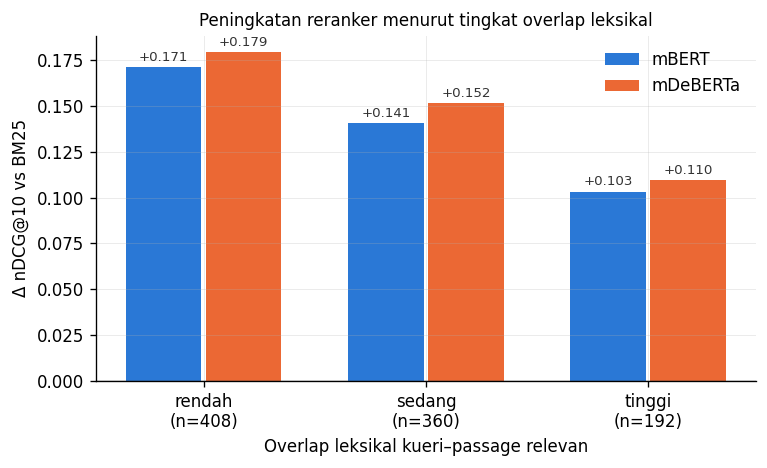

In [19]:
if have_both:
    order = [c for c in ['rendah', 'sedang', 'tinggi'] if c in by_overlap.index]
    x = np.arange(len(order)); w = 0.36
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for i, m in enumerate(['mBERT', 'mDeBERTa']):
        vals = by_overlap.loc[order, f'Δ {m}'].values
        bars = ax.bar(x + (i - 0.5) * w, vals, w - 0.02, color=COLORS[m], label=m)
        ax.bar_label(bars, fmt='%+.3f', fontsize=8, padding=2, color='#333')
    ax.axhline(0, color='#555', lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels([f'{o}\n(n={by_overlap.loc[o, "n"]})' for o in order])
    ax.set_xlabel('Overlap leksikal kueri–passage relevan'); ax.set_ylabel('Δ nDCG@10 vs BM25')
    ax.set_title('Peningkatan reranker menurut tingkat overlap leksikal', fontsize=10)
    ax.legend(frameon=False); plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/qual_overlap.png', dpi=200, bbox_inches='tight'); plt.show()

## 8. Ringkasan jawaban RQ (otomatis)

In [20]:
lines = ['# Ringkasan Hasil', '']
bm = bm25_perq['ndcg@10'].mean()
lines.append(f'- BM25 Dev nDCG@10 = {bm:.4f}')
if len(sig_ndcg):
    for _, r in sig_ndcg.iterrows():
        lines.append(f"- {r.A} vs {r.B}: Δ nDCG@10 = {r.delta:+.4f}, 95% CI {r.ci95_t}, "
                     f"{r.test} p(Holm) = {r.p_holm:.2e}, lebih efektif = {r['lebih efektif (p<.05 & |Δ|≥.01)']}")
if len(eff_table) >= 2:
    lines.append(f"- Latency k=100: mBERT {eff_table.loc['mBERT', 'Latency k=100 (ms/kueri)']:.1f} ms vs "
                 f"mDeBERTa {eff_table.loc['mDeBERTa', 'Latency k=100 (ms/kueri)']:.1f} ms per kueri")
if len(lc):
    for m in ['mBERT', 'mDeBERTa']:
        d = lc[lc.model == m]
        if len(d):
            lines.append(f'- {m} learning curve: ' + ', '.join(f"{int(f)}% = {v:.4f}" for f, v in zip(d.frac, d['ndcg@10'])))
txt = '\n'.join(lines)
open(f'{RESULTS_DIR}/summary.md', 'w').write(txt)
print(txt)

# Ringkasan Hasil

- BM25 Dev nDCG@10 = 0.4486
- mBERT vs BM25: Δ nDCG@10 = +0.1462, 95% CI [+0.1245, +0.1678], Wilcoxon p(Holm) = 8.64e-36, lebih efektif = True
- mDeBERTa vs BM25: Δ nDCG@10 = +0.1550, 95% CI [+0.1340, +0.1759], Wilcoxon p(Holm) = 1.24e-41, lebih efektif = True
- mDeBERTa vs mBERT: Δ nDCG@10 = +0.0088, 95% CI [-0.0003, +0.0179], Wilcoxon p(Holm) = 1.83e-01, lebih efektif = False
- Latency k=100: mBERT 177.2 ms vs mDeBERTa 501.1 ms per kueri
- mBERT learning curve: 25% = 0.5492, 50% = 0.5725, 100% = 0.5947
- mDeBERTa learning curve: 25% = 0.5715, 50% = 0.5891, 100% = 0.6035
